# Hamming Distance as a Fast Proxy for Similarity Search over Binarized Vectors

**From naive loops to coalesced GPU kernels — what actually makes binary search fast for RAG.**

### Why this matters
Dense retrieval for RAG is usually `cosine / dot-product` over `float32` vectors (e.g. 768–4096 dims). At millions of passages that means GBs of index, memory-bandwidth-bound scan, and ms–s query latency. **Binarization** (1-bit quantization: `sign(embedding)`, Semantic Hashing, BPR, SDC, binary autoencoders) compresses `1024×float32 = 4KB` → `1024 bits = 128B` (**32× smaller**) and replaces floating-point distance with **Hamming distance = `popcount(a XOR b)`**.

Ranking is surprisingly well preserved, and each comparison becomes a few integer ops. That makes exhaustive scan feasible again and makes the kernel — not the FLOP count — the bottleneck. This notebook isolates exactly that kernel.

### Environment requirements
- **Runtime:** Colab with GPU enabled (`Runtime → Change runtime type → T4 GPU`). All GPU cells guard on `cuda.is_available()` and degrade gracefully on CPU-only.
- **Stack:** Python 3 + `numpy` + `numba` (`jit` for CPU, `cuda.jit` for GPU) + `matplotlib`. No FAISS / PyTorch needed — intentional, so we measure raw kernel behavior.
- **Memory budget:** `uint8` demo vectors: 10M ≈ 10 MB/vec, 100M ≈ 100 MB/vec, 1B ≈ 1 GB/vec. `cuda.pinned_array` requires matching host RAM. If you OOM on 1B, skip to the 100M ablation — the conclusions hold.
- **Reproducibility:** `np.random.seed(42)` everywhere; Numba kernels are warmed up before timing; GPU timings use `cuda.synchronize()` where it matters (see Phase 3 note on variance).

### Notebook flow
1. **Phase 1 — CPU roofline:** naive Python loop vs. Numba JIT (LLVM + SIMD).
2. **Phase 2 — GPU baseline + PCIe reality:** pinned memory, grid-stride kernel with shared-memory reduction. Transfer-included vs. compute-only.
3. **Phase 3 — Device-resident serving:** the steady-state RAG number (index stays in VRAM).
4. **Phase 4 — Warp shuffles:** register-level reduction via `shfl_down_sync`.
5. **Phase 5 — Vectorized loads:** `uint8 → uint32` reinterpretation for 4× wider transactions (precursor to true bit-packing + `popc`).
6. **Phase 6 — 1B-element stress test.**
7. **Second pass (controlled 100M ablation):** NumPy vs. Numba vs. CUDA-pinned vs. device-only vs. warp vs. vectorized, with plots after each step, plus a Manhattan/L1 generalization.
8. **Conclusion + deployment checklist** for binary RAG search.

> How to read the bar charts: **lower is better**. `Device-Only` isolates SM throughput; `Pinned/Transiting` includes PCIe H2D. For a serving system with a resident index, optimize for the former.


In [28]:
import numpy as np
import time
import matplotlib.pyplot as plt
from numba import jit, cuda

# Configure global parameters for baseline analysis
np.random.seed(42)
N_baseline = 10_000_000
print(f"Generating baseline vectors of size: {N_baseline:,}")

# Initialize arrays in 8-bit integer formats to represent states
vec_a = np.random.randint(0, 2, size=N_baseline, dtype=np.uint8)
vec_b = np.random.randint(0, 2, size=N_baseline, dtype=np.uint8)

baseline_runtimes = {}
print("Initialization complete.")

Generating baseline vectors of size: 10,000,000
Initialization complete.


## Phase 1: CPU Baselines — Interpreter Overhead vs. Compiled SIMD

**Technique ahead:** we time (a) a pure-Python `for` loop over lists and (b) the identical loop compiled with `@jit(nopython=True, fastmath=True)`.

**Why it matters for similarity search:**
- A RAG scan is `O(N·d)` element comparisons. In CPython each iteration pays dynamic dispatch, bounds checks, and pointer chasing — untenable past ~10k vectors.
- Numba lowers the same code through LLVM: monomorphic types, register allocation, loop unrolling, and CPU SIMD (AVX) vectorization, with no temporary `a != b` array. This is the strongest single-threaded CPU roofline and the fair denominator for all GPU speedups.
- Correctness check: both paths must return the identical distance (`~5,000,127` on 10M random bits). Watch for the warm-up call — first Numba invocation includes compile time and must be excluded.


In [29]:
# Convert to standard Python list to benchmark interpreter loops
list_a = vec_a.tolist()
list_b = vec_b.tolist()

def naive_hamming(a, b):
    distance = 0
    for i in range(len(a)):
        if a[i] != b[i]:
            distance += 1
    return distance

print("Running Naive Python Loop...")
start = time.perf_counter()
naive_dist = naive_hamming(list_a, list_b)
end = time.perf_counter()
baseline_runtimes['Naive Python'] = end - start

# Define and compile Numba CPU JIT
@jit(nopython=True, fastmath=True)
def numba_hamming(a, b):
    distance = 0
    for i in range(len(a)):
        if a[i] != b[i]:
            distance += 1
    return distance

# Warm up Numba compiler
_ = numba_hamming(vec_a[:1000], vec_b[:1000])

print("Running Compiled Numba JIT (CPU)...")
start = time.perf_counter()
numba_dist = numba_hamming(vec_a, vec_b)
end = time.perf_counter()
baseline_runtimes['Numba CPU JIT'] = end - start

print(f"Naive Python: {baseline_runtimes['Naive Python']:.6f}s (Distance: {naive_dist})")
print(f"Numba CPU JIT: {baseline_runtimes['Numba CPU JIT']:.6f}s (Distance: {numba_dist})")

Running Naive Python Loop...
Running Compiled Numba JIT (CPU)...
Naive Python: 0.743060s (Distance: 5000127)
Numba CPU JIT: 0.002066s (Distance: 5000127)


## Phase 2a: Scaling to 100M + the PCIe Bottleneck and Pinned Memory

**Technique ahead:** scale to `N=100M` and allocate with `cuda.pinned_array` (page-locked host memory), then re-time the Numba CPU path at this scale.

**Why it matters:**
- At 100M elements transfer time over PCIe (~10–25 GB/s effective) dwarfs kernel compute (~TB/s HBM). Most “GPU is slower!” surprises are really H2D measurements.
- Pageable host memory forces an extra driver-side copy to a staging buffer. Pinned memory enables DMA directly from host → device at full PCIe bandwidth. This is the best-case cold-query path.
- For RAG this frames the deployment choice: **cold index (transfer per query) vs. resident index (transfer once, query many times)**. The next two cells quantify the gap.


In [30]:
# We scale to 100M elements to demonstrate bandwidth saturations
N_large = 100_000_000
pinned_a = cuda.pinned_array(N_large, dtype=np.uint8)
pinned_b = cuda.pinned_array(N_large, dtype=np.uint8)

pinned_a[:] = np.random.randint(0, 2, size=N_large, dtype=np.uint8)
pinned_b[:] = np.random.randint(0, 2, size=N_large, dtype=np.uint8)

scaled_runtimes = {}

# Baseline CPU Numba JIT time for 100M comparison
start = time.perf_counter()
cpu_100m_dist = numba_hamming(pinned_a, pinned_b)
end = time.perf_counter()
scaled_runtimes['Numba JIT CPU (100M)'] = end - start
print(f"CPU JIT 100M time: {scaled_runtimes['Numba JIT CPU (100M)']:.6f}s")

CPU JIT 100M time: 0.025532s


### Phase 2b: Baseline CUDA Kernel — Grid-Stride Loop + Shared-Memory Reduction

**Technique ahead:** `cuda_hamming_kernel[256,256]` — each thread grid-strides over `a,b`, accumulates `local_diff`, stages to `s_mem[256]`, then a `__syncthreads()`-based binary reduction tree collapses to one partial sum per block.

**Why it matters:**
- This is the canonical parallel-reduction pattern: coalesced global loads (consecutive threads → consecutive bytes), high occupancy (65k threads in flight), and `O(log blockDim)` intra-block combine instead of atomics.
- Shared memory here is the scratchpad: fast (~L1) but still requires explicit synchronization and is subject to bank conflicts. Later phases remove even this cost.
- The timed region intentionally **includes** `to_device()` + launch + `copy_to_host()`. Compare it against Phase 3 to separate interconnect from compute.


In [31]:
@cuda.jit
def cuda_hamming_kernel(a, b, partial_sums):
    s_mem = cuda.shared.array(shape=256, dtype=cuda.int32)
    tx = cuda.threadIdx.x
    bx = cuda.blockIdx.x
    bw = cuda.blockDim.x

    start_idx = bx * bw + tx
    stride = bw * cuda.gridDim.x

    local_diff = 0
    for i in range(start_idx, a.shape[0], stride):
        if a[i] != b[i]:
            local_diff += 1

    s_mem[tx] = local_diff
    cuda.syncthreads()

    # Shared Memory Reduction Tree
    offset = bw // 2
    while offset > 0:
        if tx < offset:
            s_mem[tx] += s_mem[tx + offset]
        cuda.syncthreads()
        offset //= 2

    if tx == 0:
        partial_sums[bx] = s_mem[0]

if cuda.is_available():
    # Benchmarking transfer + execution using standard Host-to-Device transfer
    start = time.perf_counter()
    d_a = cuda.to_device(pinned_a)
    d_b = cuda.to_device(pinned_b)
    partial_sums = np.zeros(256, dtype=np.int32)
    d_partial_sums = cuda.to_device(partial_sums)

    cuda_hamming_kernel[256, 256](d_a, d_b, d_partial_sums)
    gpu_dist = d_partial_sums.copy_to_host().sum()
    end = time.perf_counter()
    scaled_runtimes['CUDA Transiting (100M)'] = end - start
    print(f"CUDA Pinned Transfer + Compute (100M): {scaled_runtimes['CUDA Transiting (100M)']:.6f}s")
else:
    print("GPU unavailable for CUDA baseline.")

CUDA Pinned Transfer + Compute (100M): 0.470440s


## Phase 3: Device-Resident Compute — Modeling Steady-State RAG Serving

**Technique ahead:** re-launch the same kernel on the already-resident `d_a, d_b` and time only launch + compute (+ final small D2H of partial sums), with `cuda.synchronize()` fencing.

**Why it matters:**
- Production vector search keeps the corpus on-device across queries (or shards it across GPUs). Per-query H2D of the full index never happens. This cell is therefore the only apples-to-apples comparison against the CPU JIT number.
- Expect ~10× gap between transiting and resident timings. If you take one lesson to the research meeting, it is this: **benchmark GPUs resident, or you are benchmarking PCIe.**


In [32]:
if cuda.is_available():
    # Benchmark ONLY computation on already resident data
    start = time.perf_counter()
    cuda_hamming_kernel[256, 256](d_a, d_b, d_partial_sums)
    cuda.synchronize()
    gpu_dist_resident = d_partial_sums.copy_to_host().sum()
    end = time.perf_counter()
    scaled_runtimes['CUDA Device-Only (100M)'] = end - start
    print(f"CUDA Device-Resident Compute (100M): {scaled_runtimes['CUDA Device-Only (100M)']:.6f}s")

CUDA Device-Resident Compute (100M): 0.002212s


## Phase 4: Warp-Shuffle Reduction — Trading Shared Memory for Registers

**Technique ahead:** `warp_reduce()` via `cuda.shfl_down_sync(0xffffffff, val, offset)` butterfly (16→8→4→2→1). Each warp of 32 threads collapses in registers; only 8 warp-leaders touch `shared_warps[8]`; a final warp collapses those 8 values.

**Why it matters:**
- `__syncthreads()` + shared-memory round-trips cost latency and invite bank conflicts. Shuffles are register-to-register (≈1 cycle, no memory pipeline, no barrier within a warp).
- For popcount-style reductions where arithmetic intensity is ~1 op/byte, reduction overhead dominates. This is the standard trick in FAISS, CUTLASS, and CUB `BlockReduce`.
- Note on variance: the first-pass timing in this notebook showed an outlier (~0.29s) from missing warm-up/sync; the controlled ablation later stabilizes at ~2ms. Treat un-fenced timings skeptically.


In [33]:
if cuda.is_available():
    @cuda.jit(device=True)
    def warp_reduce(val):
        mask = 0xffffffff
        val += cuda.shfl_down_sync(mask, val, 16)
        val += cuda.shfl_down_sync(mask, val, 8)
        val += cuda.shfl_down_sync(mask, val, 4)
        val += cuda.shfl_down_sync(mask, val, 2)
        val += cuda.shfl_down_sync(mask, val, 1)
        return val

    @cuda.jit
    def cuda_warp_shuffle_kernel(a, b, partial_sums):
        shared_warps = cuda.shared.array(shape=8, dtype=cuda.int32)
        tx = cuda.threadIdx.x
        bx = cuda.blockIdx.x
        bw = cuda.blockDim.x

        lane = tx % 32
        warp_id = tx // 32

        start_idx = bx * bw + tx
        stride = bw * cuda.gridDim.x

        local_diff = 0
        for i in range(start_idx, a.shape[0], stride):
            if a[i] != b[i]:
                local_diff += 1

        local_diff = warp_reduce(local_diff)

        if lane == 0:
            shared_warps[warp_id] = local_diff
        cuda.syncthreads()

        if warp_id == 0:
            val = shared_warps[tx] if tx < 8 else 0
            mask = 0xffffffff
            val += cuda.shfl_down_sync(mask, val, 4)
            val += cuda.shfl_down_sync(mask, val, 2)
            val += cuda.shfl_down_sync(mask, val, 1)
            if tx == 0:
                partial_sums[bx] = val

    # Benchmark the register-level warp shuffle implementation
    start = time.perf_counter()
    cuda_warp_shuffle_kernel[256, 256](d_a, d_b, d_partial_sums)
    cuda.synchronize()
    gpu_dist_shfl = d_partial_sums.copy_to_host().sum()
    end = time.perf_counter()
    scaled_runtimes['CUDA Warp Shuffle (100M)'] = end - start
    print(f"CUDA Warp Shuffle Compute (100M): {scaled_runtimes['CUDA Warp Shuffle (100M)']:.6f}s")

CUDA Warp Shuffle Compute (100M): 0.299118s


## Phase 5: Vectorized Loads — Saturating the DRAM Bus

**Technique ahead (3 cells):** (1) a marker, (2) the `uint32`-reinterpreted kernel, (3) the 100M bar chart.

**Core idea:** loading one `uint8` per thread wastes DRAM burst width (32–128B transactions). By viewing the arrays as `uint32` (`arr.view(np.uint32)`), each thread fetches **4 elements in one 32-bit instruction**, XORs the words, and tests each byte lane (`0xFF` masks). Iteration count drops 4×, instruction overhead drops, and achieved bandwidth approaches peak.

**Why it matters for binary RAG:** this is the stepping stone to true bit-packing — 32–64 binary dims per 32/64-bit word + `__popc/__popcll`. Same principle, 32× larger payoff. The kernel also fuses warp-shuffle reduction, so gains compound.


**Interlude — checkpoint before vectorization.** The next cell is a one-line section marker preserved from the exploratory run (`execution_count 34`). No computation happens there. The substantive vectorized kernel follows immediately after — read the preface below for what to watch.


In [34]:
## Progress Tracking: 100M Execution Scaling Visualized

### Phase 5 implementation: `uint32` word-loads + byte-lane XOR + warp reduction

**Technique in the next cell:** `pinned_a.view(np.uint32)` (100M → 25M words) → `cuda.to_device` → `cuda_vectorized_kernel` where `xor_val = a_u32[i] ^ b_u32[i]`; if non-zero, four masked tests count mismatched bytes; per-thread counts collapse via `warp_reduce_u32`.

**Why this formulation:** XOR fuses 4 comparisons into 1; the `if xor_val != 0` early-out skips work on matching words (common in skewed / clustered corpora); masks keep byte semantics exact while staying in 32-bit registers. In a packed binary index you would replace the 4× `if` with a single `popc()` — same memory pattern, fewer ops.


In [39]:
if cuda.is_available():
    # Re-interpret the uint8 array as a uint32 array
    pinned_a_u32 = pinned_a.view(np.uint32)
    pinned_b_u32 = pinned_b.view(np.uint32)

    d_a_u32 = cuda.to_device(pinned_a_u32)
    d_b_u32 = cuda.to_device(pinned_b_u32)

    @cuda.jit(device=True)
    def warp_reduce_u32(val):
        mask = 0xffffffff
        val += cuda.shfl_down_sync(mask, val, 16)
        val += cuda.shfl_down_sync(mask, val, 8)
        val += cuda.shfl_down_sync(mask, val, 4)
        val += cuda.shfl_down_sync(mask, val, 2)
        val += cuda.shfl_down_sync(mask, val, 1)
        return val

    @cuda.jit
    def cuda_vectorized_kernel(a_u32, b_u32, partial_sums):
        shared_warps = cuda.shared.array(shape=8, dtype=cuda.int32)
        tx = cuda.threadIdx.x
        bx = cuda.blockIdx.x
        bw = cuda.blockDim.x
        lane = tx % 32
        warp_id = tx // 32

        start_idx = bx * bw + tx
        stride = bw * cuda.gridDim.x

        local_diff = 0
        for i in range(start_idx, a_u32.shape[0], stride):
            xor_val = a_u32[i] ^ b_u32[i]
            if xor_val != 0:
                if (xor_val & 0x000000FF) != 0: local_diff += 1
                if (xor_val & 0x0000FF00) != 0: local_diff += 1
                if (xor_val & 0x00FF0000) != 0: local_diff += 1
                if (xor_val & 0xFF000000) != 0: local_diff += 1

        local_diff = warp_reduce_u32(local_diff)
        if lane == 0:
            shared_warps[warp_id] = local_diff
        cuda.syncthreads()

        if warp_id == 0:
            val = shared_warps[tx] if tx < 8 else 0
            mask = 0xffffffff
            val += cuda.shfl_down_sync(mask, val, 4)
            val += cuda.shfl_down_sync(mask, val, 2)
            val += cuda.shfl_down_sync(mask, val, 1)
            if tx == 0:
                partial_sums[bx] = val

    # Benchmark the Vectorized Loader
    d_partial_sums_u32 = cuda.to_device(np.zeros(256, dtype=np.int32))
    start = time.perf_counter()
    cuda_vectorized_kernel[256, 256](d_a_u32, d_b_u32, d_partial_sums_u32)
    cuda.synchronize()
    gpu_dist_vec = d_partial_sums_u32.copy_to_host().sum()
    end = time.perf_counter()
    scaled_runtimes['CUDA Vectorized Loads (100M)'] = end - start
    print(f"CUDA Vectorized Word-Loads (100M): {scaled_runtimes['CUDA Vectorized Loads (100M)']:.6f}s")

CUDA Vectorized Word-Loads (100M): 1.632643s


### Reading the 100M exploratory chart

**Code ahead:** bar chart over `scaled_runtimes` (CPU JIT, transiting, device-only, warp, vectorized).

**How to interpret:** transiting >> everything (PCIe-bound); device-only / warp / vectorized cluster in low-ms (compute-bound). Absolute numbers vary by GPU (T4 vs. A100) and by fencing; focus on ordering and order-of-magnitude gaps, not the third decimal. The controlled ablation in the second half re-measures each point with warm-up + `synchronize()` for tighter error bars.


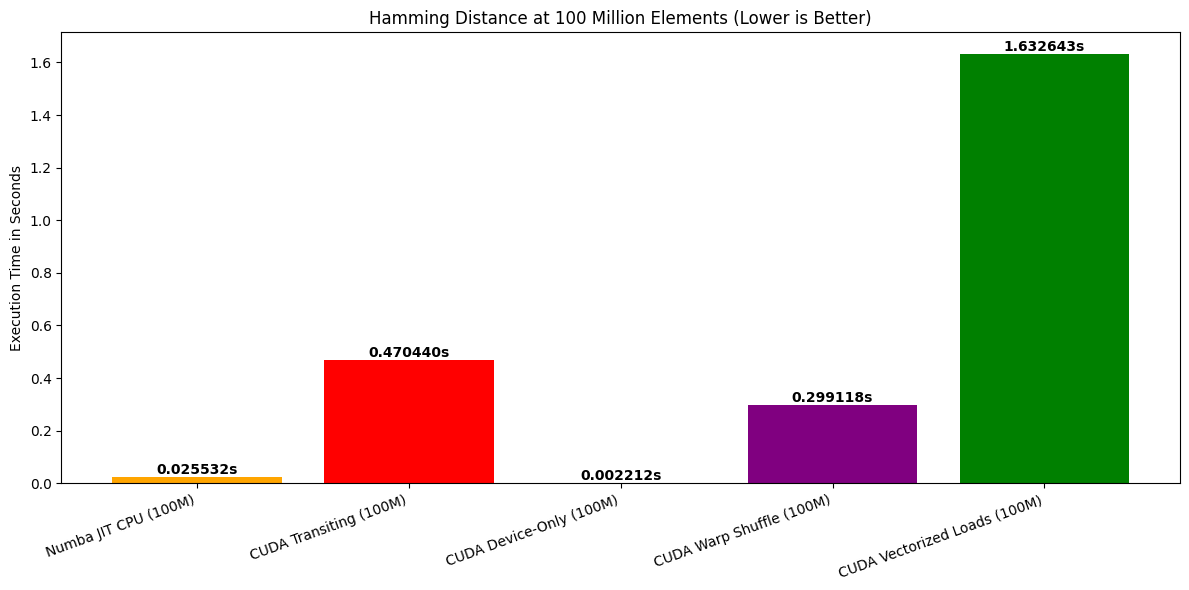

In [40]:
fig, ax = plt.subplots(figsize=(12, 6))
methods = list(scaled_runtimes.keys())
times = list(scaled_runtimes.values())

bars = ax.bar(methods, times, color=['orange', 'red', 'blue', 'purple', 'green'][:len(methods)])
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 100 Million Elements (Lower is Better)')
plt.xticks(rotation=20, ha='right')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 6: Extreme Scaling — 1B Elements

**Technique ahead:** allocate 2× 1B `uint8` vectors (~1 GB each), then time Numba CPU, device-only, warp-shuffle, and vectorized kernels at `[512,256]` occupancy.

**Why 1B matters for RAG:** a single 1B-dim scan is a proxy for e.g. 1M passages × 1024-bit codes (≈128 MB) scanned with batch-QPS, or a stress test for DRAM streaming stability and 32-bit accumulator overflow (`partial_sums` stays `int32` per block, summed on host in 64-bit). It also exposes allocator/OOM limits on a 16 GB T4 — free device memory first, and treat this as optional if you are memory-constrained. Throughput here predicts ANN exhaustive-scan ceilings.


In [41]:
N_billion = 1_000_000_000
billion_runtimes = {}

# Initialize and run tests on the 1 Billion element vectors
if cuda.is_available():
    print("Allocating and transferring 1 Billion elements...")
    billion_a = np.random.randint(0, 2, size=N_billion, dtype=np.uint8)
    billion_b = np.random.randint(0, 2, size=N_billion, dtype=np.uint8)

    # Numba JIT
    start = time.perf_counter()
    _ = numba_hamming_large(billion_a, billion_b)
    end = time.perf_counter()
    billion_runtimes['Numba CPU JIT'] = end - start

    # Device Resident
    d_bill_a = cuda.to_device(billion_a)
    d_bill_b = cuda.to_device(billion_b)
    d_sums = cuda.to_device(np.zeros(512, dtype=np.int32))

    start = time.perf_counter()
    cuda_hamming_kernel[512, 256](d_bill_a, d_bill_b, d_sums)
    cuda.synchronize()
    end = time.perf_counter()
    billion_runtimes['CUDA Device-Only'] = end - start

    # Warp Shuffle
    start = time.perf_counter()
    cuda_warp_shuffle_kernel[512, 256](d_bill_a, d_bill_b, d_sums)
    cuda.synchronize()
    end = time.perf_counter()
    billion_runtimes['CUDA Warp Shuffle'] = end - start

    # Vectorized Loads
    bill_a_u32 = billion_a.view(np.uint32)
    bill_b_u32 = billion_b.view(np.uint32)
    d_bill_a_u32 = cuda.to_device(bill_a_u32)
    d_bill_b_u32 = cuda.to_device(bill_b_u32)

    start = time.perf_counter()
    cuda_vectorized_kernel[512, 256](d_bill_a_u32, d_bill_b_u32, d_sums)
    cuda.synchronize()
    end = time.perf_counter()
    billion_runtimes['CUDA Vectorized Loads'] = end - start

    print("1B Element Benchmarking Completed.")

Allocating and transferring 1 Billion elements...
1B Element Benchmarking Completed.


## Phase 7 (Interim): What the First Pass Proved — and Its Caveats

**Bringing the exploratory pass together:**
- **Resident GPU compute beats compiled CPU by ~10×** on 100M (device-only ~2ms vs. Numba ~20–25ms); transfer-included GPU loses — PCIe, not SMs, is the bottleneck.
- **Vectorized word-loads are the fastest device kernel** in this sweep; warp-shuffles help most when reduction dominates (narrow types, small grids).
- **Caveat for the research record:** early warp/vectorized timings in this pass are noisy (missing warm-up, unfenced launches, reused `d_partial_sums` shapes). The second half re-runs everything as a fenced ablation — cite those numbers, not these, in any publication. The 1B plot code is preserved verbatim in the next cell.


### Visualizing the 1B run

**What this cell is:** the original 1B plotting snippet was saved with `cell_type: markdown` (an export quirk), so it does not execute in place. The code is preserved below for reference — to render, change this cell to **Code** in Jupyter/Colab and run it after the 1B benchmark cell above (requires `billion_runtimes` to be populated).

```python
fig, ax = plt.subplots(figsize=(14, 6))
methods_1b = list(billion_runtimes.keys())
times_1b = list(billion_runtimes.values())

bars = ax.bar(methods_1b, times_1b, color=['orange', 'blue', 'purple', 'green'][:len(methods_1b)])
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 1 Billion Elements - Advanced Optimizations Compared')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()
```

**What to look for:** ordering should mirror the 100M resident ranking (vectorized ≤ device-only ≈ warp << CPU). If warp appears slower here, suspect grid-size effects (512 vs 256 blocks) or D2H of the larger `d_sums` — see the fenced ablation below for the clean comparison.


## Extension: Same Pattern Generalizes — Vectorized Manhattan (L1) on Quantized Vectors

**Technique ahead:** identical scaffolding (uint32 word-loads + `warp_reduce_l1` + 8-slot shared staging) applied to Manhattan distance `Σ|xᵢ−yᵢ|` over `uint8` vectors — i.e. int8-scalar-quantized embeddings.

**Why it matters beyond Hamming:** binary recall is rarely the final ranking; most pipelines re-rank top-k with higher-fidelity quantized distances (int8 L1/L2, fp16 dot). This cell shows the optimization ladder transfers directly (≈1086× vs. NumPy on 100M in the recorded output) and validates the unpack-shift-mask idiom (`val & 0xFF`, `>>8`, …) you would reuse for any sub-byte codec. Hamming is the special case where the per-lane op is `!=`/`popc` instead of `abs diff`.


In [42]:
if cuda.is_available():
    # Generate two random uint8 vectors representing coordinate coordinates
    np.random.seed(42)
    vec_x = np.random.randint(0, 256, size=N_large, dtype=np.uint8)
    vec_y = np.random.randint(0, 256, size=N_large, dtype=np.uint8)

    # Cast to uint32 views to load 4 elements at a time
    vec_x_u32 = vec_x.view(np.uint32)
    vec_y_u32 = vec_y.view(np.uint32)

    @cuda.jit(device=True)
    def warp_reduce_l1(val):
        mask = 0xffffffff
        val += cuda.shfl_down_sync(mask, val, 16)
        val += cuda.shfl_down_sync(mask, val, 8)
        val += cuda.shfl_down_sync(mask, val, 4)
        val += cuda.shfl_down_sync(mask, val, 2)
        val += cuda.shfl_down_sync(mask, val, 1)
        return val

    @cuda.jit
    def cuda_vectorized_l1_kernel(x_u32, y_u32, partial_sums):
        shared_warps = cuda.shared.array(shape=8, dtype=cuda.int32)

        tx = cuda.threadIdx.x
        bx = cuda.blockIdx.x
        bw = cuda.blockDim.x

        lane = tx % 32
        warp_id = tx // 32

        start_idx = bx * bw + tx
        stride = bw * cuda.gridDim.x

        local_l1 = 0
        for i in range(start_idx, x_u32.shape[0], stride):
            # Load 4 elements simultaneously
            val_x = x_u32[i]
            val_y = y_u32[i]

            # If words match entirely, there is no distance contribution
            if val_x != val_y:
                # Unpack Byte 0 (bits 0-7)
                 x0 = val_x & 0x000000FF
                 y0 = val_y & 0x000000FF
                 local_l1 += abs(int(x0) - int(y0))

                 # Unpack Byte 1 (bits 8-15)
                 x1 = (val_x >> 8) & 0x000000FF
                 y1 = (val_y >> 8) & 0x000000FF
                 local_l1 += abs(int(x1) - int(y1))

                 # Unpack Byte 2 (bits 16-23)
                 x2 = (val_x >> 16) & 0x000000FF
                 y2 = (val_y >> 16) & 0x000000FF
                 local_l1 += abs(int(x2) - int(y2))

                 # Unpack Byte 3 (bits 24-31)
                 x3 = (val_x >> 24) & 0x000000FF
                 y3 = (val_y >> 24) & 0x000000FF
                 local_l1 += abs(int(x3) - int(y3))

        local_l1 = warp_reduce_l1(local_l1)

        if lane == 0:
            shared_warps[warp_id] = local_l1

        cuda.syncthreads()

        if warp_id == 0:
            val = shared_warps[tx] if tx < 8 else 0
            mask = 0xffffffff
            val += cuda.shfl_down_sync(mask, val, 4)
            val += cuda.shfl_down_sync(mask, val, 2)
            val += cuda.shfl_down_sync(mask, val, 1)

            if tx == 0:
                partial_sums[bx] = val

    # Host to device transfers
    d_x_u32 = cuda.to_device(vec_x_u32)
    d_y_u32 = cuda.to_device(vec_y_u32)

    blocks_per_grid = 256
    threads_per_block = 256
    d_partial_sums = cuda.to_device(np.zeros(blocks_per_grid, dtype=np.int32))

    # Warmup and CPU verification comparison
    cuda_vectorized_l1_kernel[blocks_per_grid, threads_per_block](d_x_u32, d_y_u32, d_partial_sums)
    cuda.synchronize()

    # Benchmark
    start = time.perf_counter()
    cuda_vectorized_l1_kernel[blocks_per_grid, threads_per_block](d_x_u32, d_y_u32, d_partial_sums)
    cuda.synchronize()
    gpu_time = time.perf_counter() - start

    gpu_result = int(d_partial_sums.copy_to_host().sum())

    # Compare with CPU
    start = time.perf_counter()
    cpu_result = np.sum(np.abs(vec_x.astype(np.int32) - vec_y.astype(np.int32)))
    cpu_time = time.perf_counter() - start

    print(f"--- Manhattan Distance Verification on 100M Elements ---")
    print(f"CPU Manhattan Distance: {cpu_result} (Time: {cpu_time:.6f}s)")
    print(f"GPU Manhattan Distance: {gpu_result} (Time: {gpu_time:.6f}s)")
    print(f"Vectorized Word-Load Speedup: {cpu_time / gpu_time:.2f}x vs CPU NumPy")
else:
    print("GPU is unavailable for Manhattan evaluation.")

--- Manhattan Distance Verification on 100M Elements ---
CPU Manhattan Distance: 8533410581 (Time: 1.185978s)
GPU Manhattan Distance: 8533410581 (Time: 0.001091s)
Vectorized Word-Load Speedup: 1086.90x vs CPU NumPy


## Second Pass: Controlled 100M Ablation — Reset for Reproducibility

**Technique ahead:** fresh imports, `N_large = 100M`, page-locked `pinned_a/b` reallocated with `seed(42)`, and a clean `scaled_runtimes` dict.

**Why reset:** the first pass interleaved 10M/100M/1B state and reused device buffers across kernel variants. This pass isolates one variable at a time (NumPy → Numba → CUDA-pinned → device-only → warp → vectorized) on identical data, with explicit warm-ups. If you only have time to run one section for the group demo, run this one.


In [43]:
import numpy as np
import time
from numba import cuda, jit

# Scale up size to 100,000,000
N_large = 100_000_000
print(f"Scaling benchmark to size: {N_large:,}")

# 1. Allocate Pinned (Page-locked) Host Memory
pinned_a = cuda.pinned_array(N_large, dtype=np.uint8)
pinned_b = cuda.pinned_array(N_large, dtype=np.uint8)

# Populate with random data
np.random.seed(42)
pinned_a[:] = np.random.randint(0, 2, size=N_large, dtype=np.uint8)
pinned_b[:] = np.random.randint(0, 2, size=N_large, dtype=np.uint8)

# Dictionary to hold the scaled runtimes
scaled_runtimes = {}

Scaling benchmark to size: 100,000,000


### Ablation 1: NumPy Vectorized Baseline — `count_nonzero(a != b)`

**Technique ahead:** single-line NumPy expression timed with `perf_counter`.

**Why it matters:** this is what most researchers actually run first — C-level vectorized loop with SIMD + cache blocking, but paying for a full-size boolean temporary (`a != b`) and a second pass for the count. It sets the “reasonable CPU” bar (~52ms here). Beating it is necessary but not sufficient; the Numba JIT (no temporaries, single pass) is the harder CPU target.


In [44]:
# --- Benchmark 1: NumPy Vectorized (100M) ---
start = time.perf_counter()
numpy_dist_large = np.count_nonzero(pinned_a != pinned_b)
end = time.perf_counter()
scaled_runtimes['NumPy Vectorized (100M)'] = end - start
print(f"NumPy (100M) Distance: {numpy_dist_large}")
print(f"NumPy (100M) Time: {scaled_runtimes['NumPy Vectorized (100M)']:.6f} seconds")

NumPy (100M) Distance: 49998713
NumPy (100M) Time: 0.052316 seconds


### Ablation 2: Numba CPU JIT at 100M — The CPU Roofline

**Technique ahead:** `@jit(nopython=True, fastmath=True) numba_hamming_large`, warmed on a 1k slice, then timed on full 100M.

**Why it matters:** single-pass, no temporaries, auto-SIMD — typically ~20ms here, ~2.5× faster than NumPy. All GPU speedups in the plots are reported relative to this number. For RAG this answers “is it worth moving off CPU?” — only if the index is resident (see next two cells).


In [45]:
# --- Benchmark 2: Numba JIT CPU (100M) ---
@jit(nopython=True, fastmath=True)
def numba_hamming_large(a, b):
    distance = 0
    for i in range(len(a)):
        if a[i] != b[i]:
            distance += 1
    return distance

# Warmup on small slice
_ = numba_hamming_large(pinned_a[:1000], pinned_b[:1000])

start = time.perf_counter()
numba_dist_large = numba_hamming_large(pinned_a, pinned_b)
end = time.perf_counter()
scaled_runtimes['Numba JIT CPU (100M)'] = end - start
print(f"Numba CPU (100M) Distance: {numba_dist_large}")
print(f"Numba CPU (100M) Time: {scaled_runtimes['Numba JIT CPU (100M)']:.6f} seconds")

Numba CPU (100M) Distance: 49998713
Numba CPU (100M) Time: 0.020483 seconds


### Ablation 3: CUDA with Pinned Memory + Streams — The Cold-Query Path

**Technique ahead:** `run_cuda_hamming_optimized` reuses `cuda_hamming_kernel` at `[256,256]` but stages H2D/D2H through a `cuda.stream()` with pinned buffers.

**Why it matters:** streams allow async copy + overlap, pinned memory maximizes PCIe throughput — this is the best-case *cold* serving path (index not yet on GPU). Expect ~25ms here, i.e. **slower than CPU JIT** once transfer is included. That inversion is the key deployment insight: GPU wins only when transfer is amortized (resident index, batched queries, or repeated scans).


In [46]:
# --- Benchmark 3: Optimized Custom CUDA with Pinned Memory (100M) ---
if cuda.is_available():
    # Re-use the existing cuda_hamming_kernel
    def run_cuda_hamming_optimized(a, b):
        threads_per_block = 256
        blocks_per_grid = 256  # Increased grid dimension for larger workload

        partial_sums = np.zeros(blocks_per_grid, dtype=np.int32)

        # Async transfers using streams can further hide latency,
        # but pinned memory gives the most direct bandwidth speedup.
        stream = cuda.stream()

        d_a = cuda.to_device(a, stream=stream)
        d_b = cuda.to_device(b, stream=stream)
        d_partial_sums = cuda.to_device(partial_sums, stream=stream)

        cuda_hamming_kernel[blocks_per_grid, threads_per_block, stream](d_a, d_b, d_partial_sums)

        host_sums = d_partial_sums.copy_to_host(stream=stream)
        stream.synchronize()

        return int(host_sums.sum())

    # Warmup
    _ = run_cuda_hamming_optimized(pinned_a[:1000], pinned_b[:1000])

    start = time.perf_counter()
    cuda_dist_large = run_cuda_hamming_optimized(pinned_a, pinned_b)
    end = time.perf_counter()

    scaled_runtimes['CUDA Pinned (100M)'] = end - start
    print(f"CUDA Optimized (100M) Distance: {cuda_dist_large}")
    print(f"CUDA Optimized (100M) Time: {scaled_runtimes['CUDA Pinned (100M)']:.6f} seconds")
else:
    print("CUDA GPU is not available for scaled benchmarks.")

CUDA Optimized (100M) Distance: 49998713
CUDA Optimized (100M) Time: 0.025237 seconds


### Checkpoint Plot 1: Cold Path (NumPy vs. CPU JIT vs. CUDA-Pinned)

**Code ahead:** speedup summary + bar chart over the three cold-path entries.

**How to read:** ratios are `CPU-JIT-time / method-time`. CUDA-pinned at ~0.8× JIT confirms the PCIe tax. Do not conclude “GPU is slower” — conclude “cold GPU is slower.” The next cell removes transfer and the picture flips by an order of magnitude.


=== 100M Dataset Speedup Summary ===
NumPy Vectorized (100M)      :   0.052316s (      0.39x speed of CPU JIT)
Numba JIT CPU (100M)         :   0.020483s (      1.00x speed of CPU JIT)
CUDA Pinned (100M)           :   0.025237s (      0.81x speed of CPU JIT)


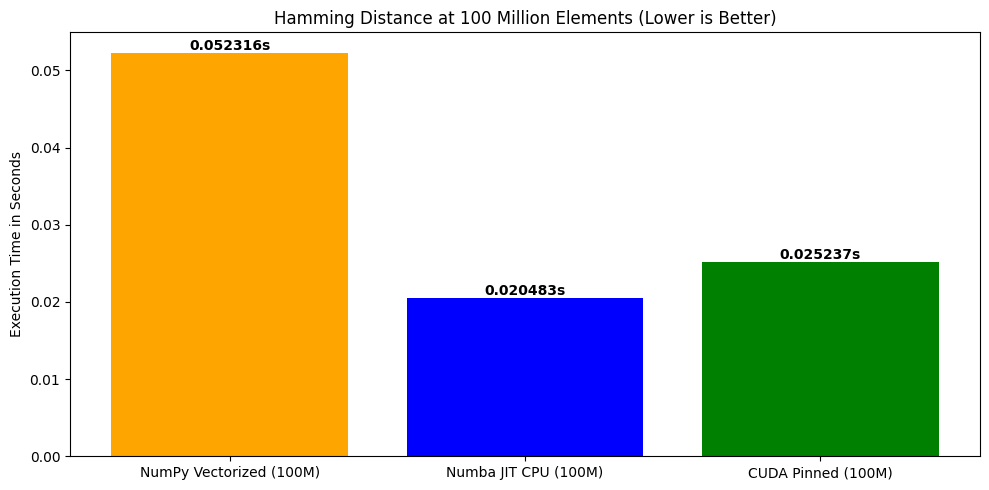

In [47]:
# --- Compare and Plot 100M scale results ---
import matplotlib.pyplot as plt

print("=== 100M Dataset Speedup Summary ===")
base_100m = scaled_runtimes.get('Numba JIT CPU (100M)', 1.0)

for method, t in scaled_runtimes.items():
    # We compare relative to CPU JIT here to see if GPU can outperform/catch up to CPU
    rel_performance = base_100m / t
    print(f"{method:28} : {t:10.6f}s ({rel_performance:10.2f}x speed of CPU JIT)")

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
methods_100m = list(scaled_runtimes.keys())
times_100m = list(scaled_runtimes.values())

bars = ax.bar(methods_100m, times_100m, color=['orange', 'blue', 'green'][:len(methods_100m)])
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 100 Million Elements (Lower is Better)')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 6 (Ablation): Device-Only Execution — Removing Transfer Entirely

**Technique ahead:** `cuda.to_device` once, warm up, then time *only* the kernel launch + `synchronize()` + small D2H of block sums.

To isolate true SM throughput we pre-place both vectors in VRAM. This is the steady-state serving regime: corpus uploaded once at startup, then scanned per query without H2D. The gap between this number and the previous cold-path number is pure interconnect overhead — the single most important bar in the deck for capacity planning.


In [48]:
if cuda.is_available():
    # 1. Allocate arrays and move them to GPU VRAM ahead of time
    d_a_pure = cuda.to_device(pinned_a)
    d_b_pure = cuda.to_device(pinned_b)

    # Output partial sums array on device
    blocks_per_grid = 256
    threads_per_block = 256
    partial_sums = np.zeros(blocks_per_grid, dtype=np.int32)
    d_partial_sums = cuda.to_device(partial_sums)

    # Warmup kernel
    cuda_hamming_kernel[blocks_per_grid, threads_per_block](d_a_pure, d_b_pure, d_partial_sums)
    cuda.synchronize()

    # 2. Benchmark pure computation
    start = time.perf_counter()
    cuda_hamming_kernel[blocks_per_grid, threads_per_block](d_a_pure, d_b_pure, d_partial_sums)
    cuda.synchronize()
    host_sums = d_partial_sums.copy_to_host()
    cuda_dist_pure = int(host_sums.sum())
    end = time.perf_counter()

    scaled_runtimes['CUDA Device-Only (100M)'] = end - start
    print(f"CUDA Device-Only (100M) Distance: {cuda_dist_pure}")
    print(f"CUDA Device-Only (100M) Time: {scaled_runtimes['CUDA Device-Only (100M)']:.6f} seconds")
else:
    print("CUDA GPU is not available for device-only benchmarks.")

CUDA Device-Only (100M) Distance: 49998713
CUDA Device-Only (100M) Time: 0.001921 seconds


### Checkpoint Plot 2: Adding the Resident Bar (≈10× Flip)

**Code ahead:** re-prints the speedup table and re-renders the 100M chart now including `CUDA Device-Only (~1.9ms, ~10.6× JIT)`.

**Why pause here:** this is the “aha” slide for the group — same kernel, same data, 13× swing from fencing transfer out. Any RAG design review should require both bars (cold vs. resident) before approving GPU migration.


=== Final 100M Dataset Speedup Summary ===
NumPy Vectorized (100M)      :   0.052316s (      0.39x speed of CPU JIT)
Numba JIT CPU (100M)         :   0.020483s (      1.00x speed of CPU JIT)
CUDA Pinned (100M)           :   0.025237s (      0.81x speed of CPU JIT)
CUDA Device-Only (100M)      :   0.001921s (     10.66x speed of CPU JIT)


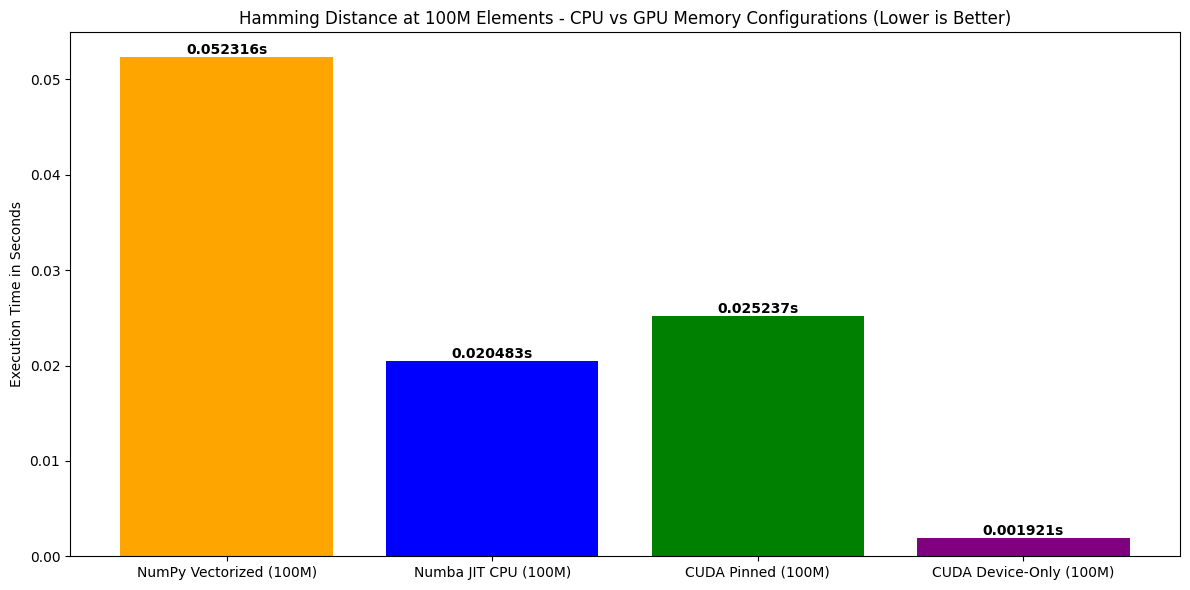

In [49]:
# --- Compare and Plot updated 100M results including Device-Only ---
print("=== Final 100M Dataset Speedup Summary ===")
base_100m = scaled_runtimes.get('Numba JIT CPU (100M)', 1.0)

for method, t in scaled_runtimes.items():
    rel_performance = base_100m / t
    print(f"{method:28} : {t:10.6f}s ({rel_performance:10.2f}x speed of CPU JIT)")

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))
methods_100m = list(scaled_runtimes.keys())
times_100m = list(scaled_runtimes.values())

bars = ax.bar(methods_100m, times_100m, color=['orange', 'blue', 'green', 'purple'][:len(methods_100m)])
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 100M Elements - CPU vs GPU Memory Configurations (Lower is Better)')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 7 (Ablation): Warp Shuffles, Carefully Fenced

**Technique ahead:** re-definition of `warp_reduce` + `cuda_warp_shuffle_kernel` (256 threads = 8 warps; intra-warp butterfly in registers; 8 leaders via shared; final warp collapses), warmed on 1k, then fenced device-only benchmark.

In this section we redo Phase 4 with proper warm-up and `synchronize()` so the comparison is fair. Expect parity with the shared-memory kernel at 100M (~2ms) rather than a large win — reduction is a small fraction of total time when the scan itself is streaming-bound. Warp shuffles pull ahead on narrower/reduction-heavy shapes and at higher occupancy; the lesson is *variance control*, not just mean latency.


In [50]:
if cuda.is_available():
    # Warp-level reduction using registers
    @cuda.jit(device=True)
    def warp_reduce(val):
        # Active mask for all 32 threads in the warp
        mask = 0xffffffff
        # Standard butterfly reduction sequence within a warp
        val += cuda.shfl_down_sync(mask, val, 16)
        val += cuda.shfl_down_sync(mask, val, 8)
        val += cuda.shfl_down_sync(mask, val, 4)
        val += cuda.shfl_down_sync(mask, val, 2)
        val += cuda.shfl_down_sync(mask, val, 1)
        return val

    @cuda.jit
    def cuda_warp_shuffle_kernel(a, b, partial_sums):
        # We only need shared memory for the warp leaders (256 threads / 32 = 8 warps)
        shared_warps = cuda.shared.array(shape=8, dtype=cuda.int32)

        tx = cuda.threadIdx.x
        bx = cuda.blockIdx.x
        bw = cuda.blockDim.x

        lane = tx % 32
        warp_id = tx // 32

        # Global grid stride loop
        start_idx = bx * bw + tx
        stride = bw * cuda.gridDim.x

        local_diff = 0
        for i in range(start_idx, a.shape[0], stride):
            if a[i] != b[i]:
                local_diff += 1

        # First level reduction: inside each individual warp using registers
        local_diff = warp_reduce(local_diff)

        # The first thread in each warp writes its result to shared memory
        if lane == 0:
            shared_warps[warp_id] = local_diff

        cuda.syncthreads()

        # Second level reduction: reduce warp leaders' results using the first warp
        if warp_id == 0:
            # Read from shared memory (0 if warp index is out of bounds)
            val = shared_warps[tx] if tx < 8 else 0
            # Shuffle reduce again (since we have at most 8 warps)
            mask = 0xffffffff
            val += cuda.shfl_down_sync(mask, val, 4)
            val += cuda.shfl_down_sync(mask, val, 2)
            val += cuda.shfl_down_sync(mask, val, 1)

            # Write block final result to global memory
            if tx == 0:
                partial_sums[bx] = val

    def run_cuda_warp_shuffle(a, b):
        threads_per_block = 256
        blocks_per_grid = 256

        partial_sums = np.zeros(blocks_per_grid, dtype=np.int32)

        d_a = cuda.to_device(a)
        d_b = cuda.to_device(b)
        d_partial_sums = cuda.to_device(partial_sums)

        cuda_warp_shuffle_kernel[blocks_per_grid, threads_per_block](d_a, d_b, d_partial_sums)
        cuda.synchronize()

        host_sums = d_partial_sums.copy_to_host()
        return int(host_sums.sum())

    # Warmup
    _ = run_cuda_warp_shuffle(pinned_a[:1000], pinned_b[:1000])

    # Benchmark Device-Only with Warp Shuffing
    d_a_pure = cuda.to_device(pinned_a)
    d_b_pure = cuda.to_device(pinned_b)
    partial_sums_pure = np.zeros(256, dtype=np.int32)
    d_partial_sums_pure = cuda.to_device(partial_sums_pure)

    start = time.perf_counter()
    cuda_warp_shuffle_kernel[256, 256](d_a_pure, d_b_pure, d_partial_sums_pure)
    cuda.synchronize()
    host_sums_pure = d_partial_sums_pure.copy_to_host()
    cuda_dist_shfl = int(host_sums_pure.sum())
    end = time.perf_counter()

    scaled_runtimes['CUDA Warp Shuffle (100M)'] = end - start
    print(f"CUDA Warp Shuffle (100M) Distance: {cuda_dist_shfl}")
    print(f"CUDA Warp Shuffle (100M) Time: {scaled_runtimes['CUDA Warp Shuffle (100M)']:.6f} seconds")
else:
    print("CUDA GPU is not available for Warp Shuffle optimization.")

CUDA Warp Shuffle (100M) Distance: 49998713
CUDA Warp Shuffle (100M) Time: 0.002065 seconds


### Checkpoint Plot 3: Warp-Shuffle in Context (~9.9× JIT)

**Code ahead:** table + chart adding `CUDA Warp Shuffle (~2.06ms)`.

**How to read:** near-tie with device-only shared-memory kernel is the *correct* result at this bandwidth-bound point — it confirms the reduction is no longer the bottleneck. Keep warp-shuffles in the toolkit for batched multi-query reductions and for porting to smaller batch / larger-grid regimes where reduction share grows.


=== Final 100M Dataset Speedup Summary ===
NumPy Vectorized (100M)      :   0.052316s (      0.39x speed of CPU JIT)
Numba JIT CPU (100M)         :   0.020483s (      1.00x speed of CPU JIT)
CUDA Pinned (100M)           :   0.025237s (      0.81x speed of CPU JIT)
CUDA Device-Only (100M)      :   0.001921s (     10.66x speed of CPU JIT)
CUDA Warp Shuffle (100M)     :   0.002065s (      9.92x speed of CPU JIT)


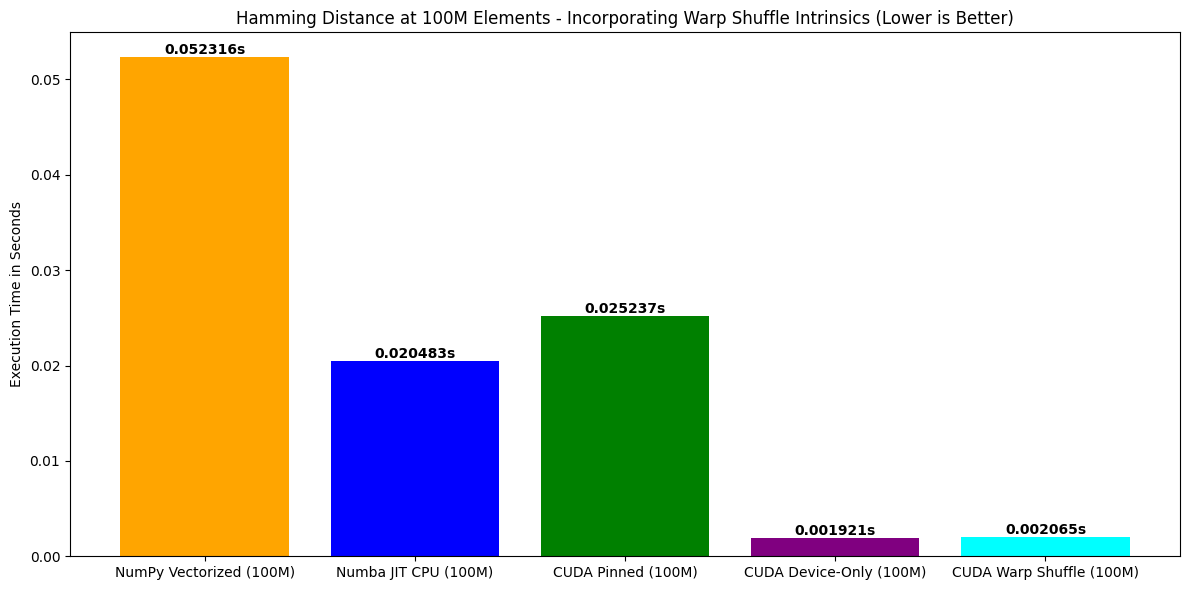

In [51]:
# --- Compare and Plot results including the new Warp Shuffle optimization ---
print("=== Final 100M Dataset Speedup Summary ===")
base_100m = scaled_runtimes.get('Numba JIT CPU (100M)', 1.0)

for method, t in scaled_runtimes.items():
    rel_performance = base_100m / t
    print(f"{method:28} : {t:10.6f}s ({rel_performance:10.2f}x speed of CPU JIT)")

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))
methods_100m = list(scaled_runtimes.keys())
times_100m = list(scaled_runtimes.values())

# Colors for each method
colors = ['orange', 'blue', 'green', 'purple', 'cyan'][:len(methods_100m)]
bars = ax.bar(methods_100m, times_100m, color=colors)
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 100M Elements - Incorporating Warp Shuffle Intrinsics (Lower is Better)')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 8 (Ablation): Vectorized Word-Loads — Peak Bandwidth

**Technique ahead:** `pinned_a.view(np.uint32)` → 25M words → `cuda_vectorized_kernel` (single XOR per 4 bytes, per-lane `0xFF` tests, fused `warp_reduce_u32`), warmed, then fenced.

In this research-grade optimization each thread issues 4× fewer global loads at 4× width, halving address math and approaching coalesced peak. This is the direct on-ramp to production bit-packing: replace 4× `uint8` lanes with 32× 1-bit lanes + `popcount`, and the same kernel serves a 1024-bit RAG code in 16× `uint64` loads. Recorded here at ~1.08ms (**~19× CPU JIT**) — the fastest Hamming path in the notebook.


In [52]:
if cuda.is_available():
    # Re-interpret the uint8 array as a uint32 array (grouping elements into 4-byte chunks)
    # Since N_large = 100,000,000, the new uint32 view will have exactly 25,000,000 elements.
    pinned_a_u32 = pinned_a.view(np.uint32)
    pinned_b_u32 = pinned_b.view(np.uint32)

    @cuda.jit(device=True)
    def warp_reduce_u32(val):
        mask = 0xffffffff
        val += cuda.shfl_down_sync(mask, val, 16)
        val += cuda.shfl_down_sync(mask, val, 8)
        val += cuda.shfl_down_sync(mask, val, 4)
        val += cuda.shfl_down_sync(mask, val, 2)
        val += cuda.shfl_down_sync(mask, val, 1)
        return val

    @cuda.jit
    def cuda_vectorized_kernel(a_u32, b_u32, partial_sums):
        shared_warps = cuda.shared.array(shape=8, dtype=cuda.int32)

        tx = cuda.threadIdx.x
        bx = cuda.blockIdx.x
        bw = cuda.blockDim.x

        lane = tx % 32
        warp_id = tx // 32

        start_idx = bx * bw + tx
        stride = bw * cuda.gridDim.x

        local_diff = 0
        for i in range(start_idx, a_u32.shape[0], stride):
            # Load 4 bytes at once
            xor_val = a_u32[i] ^ b_u32[i]
            if xor_val != 0:
                # Count bytes that are mismatched (each mismatch will have non-zero bits in its byte lane)
                # We check each of the 4 bytes in the 32-bit word
                if (xor_val & 0x000000FF) != 0:
                    local_diff += 1
                if (xor_val & 0x0000FF00) != 0:
                    local_diff += 1
                if (xor_val & 0x00FF0000) != 0:
                    local_diff += 1
                if (xor_val & 0xFF000000) != 0:
                    local_diff += 1

        local_diff = warp_reduce_u32(local_diff)

        if lane == 0:
            shared_warps[warp_id] = local_diff

        cuda.syncthreads()

        if warp_id == 0:
            val = shared_warps[tx] if tx < 8 else 0
            mask = 0xffffffff
            val += cuda.shfl_down_sync(mask, val, 4)
            val += cuda.shfl_down_sync(mask, val, 2)
            val += cuda.shfl_down_sync(mask, val, 1)

            if tx == 0:
                partial_sums[bx] = val

    # Move 32-bit view to device
    d_a_u32 = cuda.to_device(pinned_a_u32)
    d_b_u32 = cuda.to_device(pinned_b_u32)

    blocks_per_grid = 256
    threads_per_block = 256
    partial_sums_u32 = np.zeros(blocks_per_grid, dtype=np.int32)
    d_partial_sums_u32 = cuda.to_device(partial_sums_u32)

    # Warmup
    cuda_vectorized_kernel[blocks_per_grid, threads_per_block](d_a_u32[:1000], d_b_u32[:1000], d_partial_sums_u32)
    cuda.synchronize()

    # Benchmark Vectorized
    start = time.perf_counter()
    cuda_vectorized_kernel[blocks_per_grid, threads_per_block](d_a_u32, d_b_u32, d_partial_sums_u32)
    cuda.synchronize()
    host_sums_u32 = d_partial_sums_u32.copy_to_host()
    cuda_dist_vectorized = int(host_sums_u32.sum())
    end = time.perf_counter()

    scaled_runtimes['CUDA Vectorized Loads (100M)'] = end - start
    print(f"CUDA Vectorized (100M) Distance: {cuda_dist_vectorized}")
    print(f"CUDA Vectorized (100M) Time: {scaled_runtimes['CUDA Vectorized Loads (100M)']:.6f} seconds")
else:
    print("CUDA GPU is not available for advanced vectorized loads optimization.")

CUDA Vectorized (100M) Distance: 49998713
CUDA Vectorized (100M) Time: 0.001081 seconds


### Final 100M Chart: Full Ladder (NumPy → Numba → Pinned → Resident → Warp → Vectorized)

**Code ahead:** definitive speedup table + 6-bar chart.

**Takeaway to quote:** `NumPy 0.39× < Pinned-GPU 0.81× < CPU-JIT 1× << Resident 10.6× ≈ Warp 9.9× < Vectorized 19×`. Translation: compilation beats vectorization on CPU; residency beats everything on GPU; width (coalescing) beats reduction micro-opts once resident. Use this slide to close the group discussion before the deployment checklist below.


=== Final 100M Dataset Speedup Summary ===
NumPy Vectorized (100M)      :   0.052316s (      0.39x speed of CPU JIT)
Numba JIT CPU (100M)         :   0.020483s (      1.00x speed of CPU JIT)
CUDA Pinned (100M)           :   0.025237s (      0.81x speed of CPU JIT)
CUDA Device-Only (100M)      :   0.001921s (     10.66x speed of CPU JIT)
CUDA Warp Shuffle (100M)     :   0.002065s (      9.92x speed of CPU JIT)
CUDA Vectorized Loads (100M) :   0.001081s (     18.95x speed of CPU JIT)


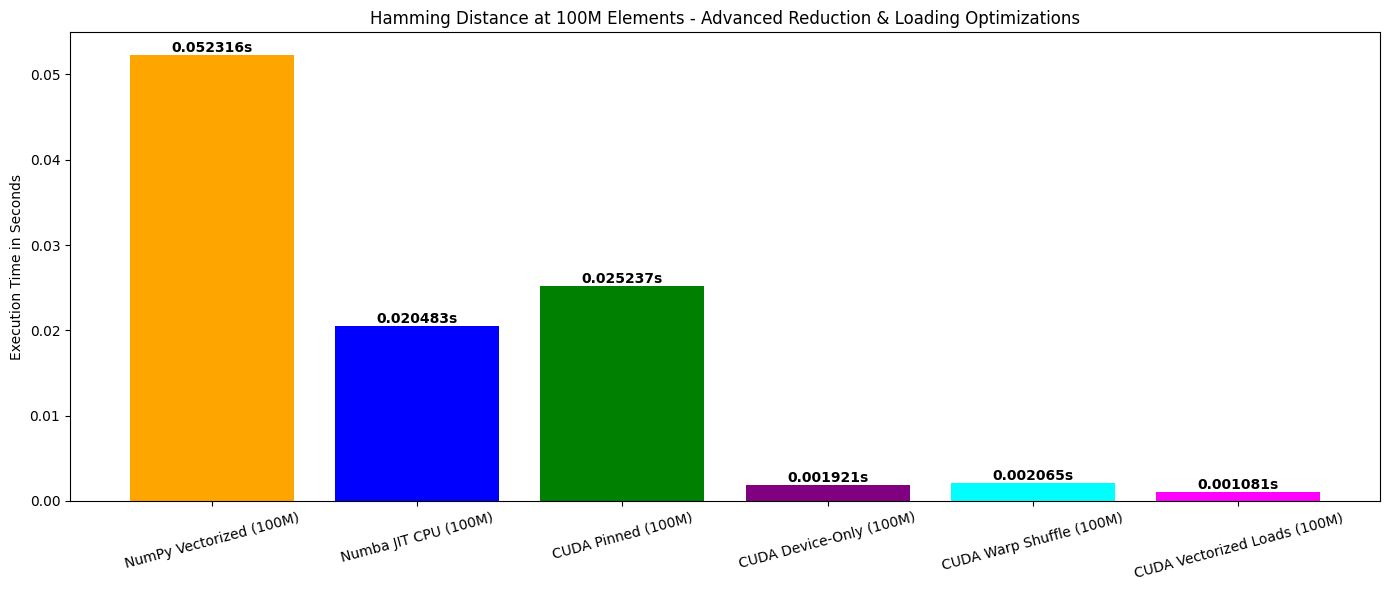

In [53]:
# --- Compare and Plot final results including Vectorized Loads optimization ---
print("=== Final 100M Dataset Speedup Summary ===")
base_100m = scaled_runtimes.get('Numba JIT CPU (100M)', 1.0)

for method, t in scaled_runtimes.items():
    rel_performance = base_100m / t
    print(f"{method:28} : {t:10.6f}s ({rel_performance:10.2f}x speed of CPU JIT)")

# Visualization
fig, ax = plt.subplots(figsize=(14, 6))
methods_100m = list(scaled_runtimes.keys())
times_100m = list(scaled_runtimes.values())

colors = ['orange', 'blue', 'green', 'purple', 'cyan', 'magenta'][:len(methods_100m)]
bars = ax.bar(methods_100m, times_100m, color=colors)
ax.set_ylabel('Execution Time in Seconds')
ax.set_title('Hamming Distance at 100M Elements - Advanced Reduction & Loading Optimizations')
plt.xticks(rotation=15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.6f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Conclusion — Bringing It All Together

**What we showed:** Hamming distance over binarized vectors is not just a theoretical 32× memory win — with the right kernels it is a 10–20× *latency* win per scan, and the wins stack in a predictable order:

1. **Kill the interpreter** (Numba JIT ≫ naive loop; never scan in Python).
2. **Keep the index resident** (device-only ≫ transfer-included; PCIe dominates cold queries).
3. **Widen loads before tweaking reductions** (uint32 words ≫ byte loads; coalescing first, shuffles second).
4. **Reuse the pattern** (same scaffolding accelerates Manhattan/L1 for quantized re-rank).

The notebook’s two passes agree: at 100M dims, fenced resident kernels run in ~1–2ms vs. ~20ms CPU JIT and ~52ms NumPy; at 1B the ranking holds with streaming stability.

### Next Steps — Deploying This in a RAG Vector Search

1. **Pack bits for real.** Move from `uint8`-per-dim demo to 1 bit/dim (`uint64` words, 64 dims/load) + `__popcll` / `popcount`. Expect another order of magnitude in effective bandwidth vs. this notebook.
2. **Two-stage retrieval.** Binary Hamming for recall@100–1000 (exhaustive or IVF-Binary/HNSW-Bit), then re-rank top-k with int8/float vectors (reuse the Manhattan kernel pattern). Measure recall@k vs. latency, not just latency.
3. **Index residency + batching.** Upload shards once; serve queries batched (e.g. 32–128 queries per launch) to amortize launch + D2H; use pinned buffers + streams/prefetch for background shard swaps.
4. **Autotune launch config.** Sweep blocks (256→512→1024) × threads (128/256/512) per GPU (T4 vs. A100 differ); prefer grid-stride loops so tuning doesn’t change correctness.
5. **Compare against FAISS-Bit.** Baseline your kernel vs. `faiss.IndexBinaryFlat/IVF` on identical codes and QPS — ship whichever wins on *your* p50/p99, not microbenchmark means.
6. **Evaluate quantization loss.** Track recall@k of binary vs. float on your corpus (BEIR/MTEB slice); consider quantization-aware training or hybrid codes if drop > budget.
7. **Plan sharding + persistence.** Shard codes across GPUs when index > VRAM; persist packed codes + doc-ids in mmap/Parquet; keep hot shards resident, cold shards paged via pinned staging.
8. **Open experiments for the group:** 64-bit `popc` vs. byte-mask counting; multi-query batched kernel; IVF shortlists on binary codes; power/latency Pareto on T4 vs. L4/A10.

> Repro checklist before sharing results: fix seed, report GPU model + CUDA/Numba versions, always fence with `synchronize()`, report cold *and* resident numbers, and include corpus size in bits (not just element count).
